<h3>Undersampling for regression - case diamonds data</h3>

**TODO: rewrite comments and clean up unnecessary code sections**

In [1]:
import os
import random
import numpy as np
# seed = 153262
seed = 7891432
os.environ['PYTHONHASHSEED'] = str(seed)      
random.seed(seed)                             
np.random.seed(seed)

In [2]:
# imports, load data etc. here

# by default, we'll use Python 3.12
# many of the sampling tools are in this module install it first:
# pip install imbalanced-learn

<b>Imports + load data, drop some columns</b>

In [3]:
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split


# 3. One-hot encode categorical variables
# Categorical columns: 'cut', 'color', 'clarity'
# diamonds_encoded = pd.get_dummies(diamonds, columns=['cut', 'color', 'clarity'], drop_first=True)

# switch to decimal format in pandas for easier values in describe()
pd.set_option('display.float_format', '{:.2f}'.format)

# load the data
df = pd.read_csv("../../houses.csv")
df = df.drop(["id", "date", "zipcode", "lat", "long"], axis=1)
df.head()

# Apply transformations only to num_cols, leave bool_cols untouched



df


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
0,221900.00,3,1.00,1180,5650,1.00,0,0,3,7,1180,0,1955,0,1340,5650
1,538000.00,3,2.25,2570,7242,2.00,0,0,3,7,2170,400,1951,1991,1690,7639
2,180000.00,2,1.00,770,10000,1.00,0,0,3,6,770,0,1933,0,2720,8062
3,604000.00,4,3.00,1960,5000,1.00,0,0,5,7,1050,910,1965,0,1360,5000
4,510000.00,3,2.00,1680,8080,1.00,0,0,3,8,1680,0,1987,0,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.00,3,2.50,1530,1131,3.00,0,0,3,8,1530,0,2009,0,1530,1509
21609,400000.00,4,2.50,2310,5813,2.00,0,0,3,8,2310,0,2014,0,1830,7200
21610,402101.00,2,0.75,1020,1350,2.00,0,0,3,7,1020,0,2009,0,1020,2007
21611,400000.00,3,2.50,1600,2388,2.00,0,0,3,8,1600,0,2004,0,1410,1287


<b>We have 21k+ houses in this data, so undersampling should be a good idea to try</b>

<b>Remove some outliers, since there are quite many on the high-end in this dataset</b>

In [4]:
# we'll aim to get this closer to a normal distribution
# current distribution is right-skewed heavily

# removing some outliers first to make it easier to undesrample in the future
# can process the whole dataset 
# and compares variables to each other instead
# of focusing on outliers on a single variable
from sklearn.ensemble import IsolationForest

# adjust the contamination rate as you see fit
# for example, if you expect 5% of the data to be outliers
# you can use 0.05 etc. 
iso = IsolationForest(contamination=0.03) 

# fit isolation forest
y_pred = iso.fit_predict(df)

# filter outliers only
outliers = df[y_pred != 1]
df = df.drop(outliers.index)

In [5]:
# outliers

<Axes: xlabel='price', ylabel='Count'>

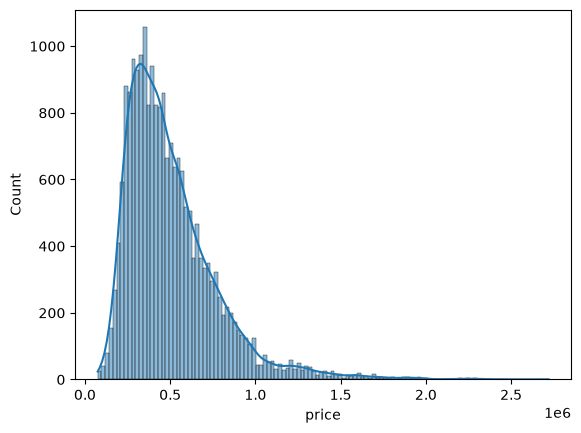

In [6]:
# histogram to see the distribution of target variable
sns.histplot(data=df, x="price", kde=True)

<b>Let's remove even more from the high end</b>

In [7]:
# after outlier removal
# mean 472265
# deviation 207983
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
count,20964.00,20964.00,20964.00,20964.00,20964.00,20964.00,20964.00,20964.00,20964.00,20964.00,20964.00,20964.00,20964.00,20964.00,20964.00,20964.00
mean,506909.14,3.35,2.07,2011.51,12769.02,1.48,0.00,0.19,3.41,7.59,1737.18,274.33,1970.98,71.31,1949.10,11242.87
std,271507.80,0.91,0.72,798.13,28131.20,0.54,0.05,0.67,0.65,1.09,748.80,414.04,29.25,370.49,638.68,19970.55
min,75000.00,0.00,0.00,290.00,520.00,1.00,0.00,0.00,1.00,1.00,290.00,0.00,1900.00,0.00,460.00,651.00
25%,319000.00,3.00,1.50,1410.00,5000.00,1.00,0.00,0.00,3.00,7.00,1180.00,0.00,1952.00,0.00,1480.00,5060.00
50%,445000.00,3.00,2.25,1890.00,7503.50,1.00,0.00,0.00,3.00,7.00,1540.00,0.00,1975.00,0.00,1820.00,7555.00
75%,625000.00,4.00,2.50,2490.00,10319.00,2.00,0.00,0.00,4.00,8.00,2150.00,530.00,1996.00,0.00,2320.00,9900.00
max,2720000.00,33.00,7.50,5960.00,1024068.00,3.50,1.00,4.00,5.00,12.00,5844.00,2220.00,2015.00,2015.00,5790.00,434728.00


In [8]:
# variation is a bit high for easy comparison
# 43 256 936 526 (43 billion etc.)
df.var()

price           73716487625.06
bedrooms                  0.82
bathrooms                 0.52
sqft_living          637017.20
sqft_lot          791364587.58
floors                    0.29
waterfront                0.00
view                      0.44
condition                 0.42
grade                     1.19
sqft_above           560707.16
sqft_basement        171430.40
yr_built                855.30
yr_renovated         137259.65
sqft_living15        407907.58
sqft_lot15        398822828.18
dtype: float64

In [9]:
# ALSO CHECK CORRELATION MATRIX BEFORE UNDERSAMPLING
df.corr()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
price,1.00,0.29,0.47,0.64,0.06,0.26,0.08,0.29,0.04,0.65,0.55,0.24,0.06,0.07,0.57,0.05
bedrooms,0.29,1.00,0.50,0.58,0.03,0.16,-0.02,0.05,0.03,0.33,0.47,0.28,0.16,0.00,0.38,0.03
bathrooms,0.47,0.50,1.00,0.73,0.05,0.51,0.00,0.12,-0.14,0.63,0.65,0.23,0.54,0.02,0.54,0.04
sqft_living,0.64,0.58,0.73,1.00,0.14,0.35,0.01,0.20,-0.07,0.73,0.86,0.37,0.35,0.01,0.75,0.14
sqft_lot,0.06,0.03,0.05,0.14,1.00,-0.03,0.01,0.01,-0.01,0.09,0.16,-0.01,0.05,-0.01,0.15,0.67
floors,0.26,0.16,0.51,0.35,-0.03,1.00,-0.00,-0.00,-0.27,0.46,0.53,-0.29,0.51,-0.01,0.27,-0.04
waterfront,0.08,-0.02,0.00,0.01,0.01,-0.00,1.00,0.27,0.02,0.01,-0.00,0.02,-0.02,-0.01,0.02,0.02
view,0.29,0.05,0.12,0.20,0.01,-0.00,0.27,1.00,0.04,0.18,0.08,0.23,-0.06,0.03,0.22,0.01
condition,0.04,0.03,-0.14,-0.07,-0.01,-0.27,0.02,0.04,1.00,-0.16,-0.18,0.19,-0.36,-0.06,-0.10,0.00
grade,0.65,0.33,0.63,0.73,0.09,0.46,0.01,0.18,-0.16,1.00,0.73,0.09,0.47,-0.02,0.69,0.09


In [10]:
# outliers

In [11]:
df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
0,221900.00,3,1.00,1180,5650,1.00,0,0,3,7,1180,0,1955,0,1340,5650
1,538000.00,3,2.25,2570,7242,2.00,0,0,3,7,2170,400,1951,1991,1690,7639
2,180000.00,2,1.00,770,10000,1.00,0,0,3,6,770,0,1933,0,2720,8062
3,604000.00,4,3.00,1960,5000,1.00,0,0,5,7,1050,910,1965,0,1360,5000
4,510000.00,3,2.00,1680,8080,1.00,0,0,3,8,1680,0,1987,0,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.00,3,2.50,1530,1131,3.00,0,0,3,8,1530,0,2009,0,1530,1509
21609,400000.00,4,2.50,2310,5813,2.00,0,0,3,8,2310,0,2014,0,1830,7200
21610,402101.00,2,0.75,1020,1350,2.00,0,0,3,7,1020,0,2009,0,1020,2007
21611,400000.00,3,2.50,1600,2388,2.00,0,0,3,8,1600,0,2004,0,1410,1287


<b>After outlier removal, we'll see the current distribution</b>

<Axes: xlabel='price', ylabel='Count'>

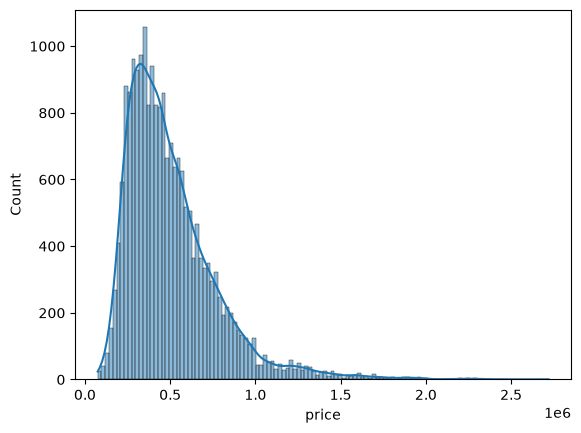

In [12]:
sns.histplot(data=df, x="price", kde=True)

In [13]:
df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
0,221900.00,3,1.00,1180,5650,1.00,0,0,3,7,1180,0,1955,0,1340,5650
1,538000.00,3,2.25,2570,7242,2.00,0,0,3,7,2170,400,1951,1991,1690,7639
2,180000.00,2,1.00,770,10000,1.00,0,0,3,6,770,0,1933,0,2720,8062
3,604000.00,4,3.00,1960,5000,1.00,0,0,5,7,1050,910,1965,0,1360,5000
4,510000.00,3,2.00,1680,8080,1.00,0,0,3,8,1680,0,1987,0,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.00,3,2.50,1530,1131,3.00,0,0,3,8,1530,0,2009,0,1530,1509
21609,400000.00,4,2.50,2310,5813,2.00,0,0,3,8,2310,0,2014,0,1830,7200
21610,402101.00,2,0.75,1020,1350,2.00,0,0,3,7,1020,0,2009,0,1020,2007
21611,400000.00,3,2.50,1600,2388,2.00,0,0,3,8,1600,0,2004,0,1410,1287


<b>Undersampling for regression - we need to create a temporary CATEGORICAL variable on TARGET REGRESSION VARIABLE</b>

<b>Finally, compare the statistics in order to see if the dataset still is close to original in its representation</b>

<b>Since we altered the target distribution heavily, we can expect basic statistics like mean, median, standard deviation and variation to change.</b>
<p>
However, correlations regarding the price-variable seem to be 99% the same! (which is promising). A good idea would also to check the phik-matrix before and after undersampling.
</p>

**TEST ML WITH THIS**

In [14]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
import sklearn.metrics as metrics
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

import seaborn as sns
import xgboost as xgb


c:\Users\tuomas.valtanen\dataeng_advda2026_lectures\DataEngineering_AdvDA_2026\.venv\Lib\site-packages\xgboost\compat.py:105: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [15]:
# X/y 
X = df.drop("price", axis=1)
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# model1 = xgb.XGBRegressor(objective='reg:squarederror')
#model1 = LinearRegression()
model1 = RandomForestRegressor()
model1.fit(X_train, y_train)
predictions = model1.predict(X_test)

# RMSE - Root mean square error
print('\nRMSE:')
print(round(np.sqrt(metrics.mean_squared_error(y_test, predictions)), 2), "$")

# R-squared. 0 = the model descibes the dataset poorly
# 1 = model describes the dataset perfectly
print('\nR-squared:')
print(round(metrics.r2_score(y_test, predictions), 2))



RMSE:
153017.65 $

R-squared:
0.67


In [16]:
df.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
0,221900.00,3,1.00,1180,5650,1.00,0,0,3,7,1180,0,1955,0,1340,5650
1,538000.00,3,2.25,2570,7242,2.00,0,0,3,7,2170,400,1951,1991,1690,7639
2,180000.00,2,1.00,770,10000,1.00,0,0,3,6,770,0,1933,0,2720,8062
3,604000.00,4,3.00,1960,5000,1.00,0,0,5,7,1050,910,1965,0,1360,5000
4,510000.00,3,2.00,1680,8080,1.00,0,0,3,8,1680,0,1987,0,1800,7503


In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler, PowerTransformer, RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics

# 1. Split features and target
X = df.drop("price", axis=1)
y = df['price'].values.reshape(-1, 1)  # reshape needed for PowerTransformer

# 2. Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Scale features
x_scaler = RobustScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# 4. Initialize PowerTransformer with Yeo-Johnson
y_transformer = PowerTransformer(method='yeo-johnson', standardize=False)
y_train_trans = y_transformer.fit_transform(y_train)

# 5. Transform test target (optional, just for reference)
y_test_trans = y_transformer.transform(y_test)

# 6. Train model on transformed target
model = RandomForestRegressor()
model.fit(X_train_scaled, y_train_trans.ravel())

# 7. Predict on test set (transformed space)
predictions_trans = model.predict(X_test_scaled)

# 8. Inverse transform predictions back to original scale
predictions = y_transformer.inverse_transform(predictions_trans.reshape(-1, 1)).ravel()

# 9. Evaluate on original scale
rmse = np.sqrt(metrics.mean_squared_error(y_test.ravel(), predictions))
r2 = metrics.r2_score(y_test.ravel(), predictions)

print('\nRMSE:')
print(round(rmse, 2), "$")

print('\nR-squared:')
print(round(r2, 2))

# the model got slightly worse


RMSE:
154460.96 $

R-squared:
0.66


In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler, PowerTransformer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics

# 1. Split features and target
X = df.drop("price", axis=1)
y = df['price'].values.reshape(-1, 1)  # reshape needed for PowerTransformer

# 2. Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Scale features
x_scaler = MinMaxScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# 4. Initialize PowerTransformer with Yeo-Johnson
y_transformer = PowerTransformer(method='yeo-johnson', standardize=False)
y_train_trans = y_transformer.fit_transform(y_train)

# 5. Transform test target (optional, just for reference)
y_test_trans = y_transformer.transform(y_test)

# 6. Train model on transformed target
model = RandomForestRegressor()
model.fit(X_train_scaled, y_train_trans.ravel())

# 7. Predict on test set (transformed space)
predictions_trans = model.predict(X_test_scaled)

# 8. Inverse transform predictions back to original scale
predictions = y_transformer.inverse_transform(predictions_trans.reshape(-1, 1)).ravel()

# 9. Evaluate on original scale
rmse = np.sqrt(metrics.mean_squared_error(y_test.ravel(), predictions))
r2 = metrics.r2_score(y_test.ravel(), predictions)

print('\nRMSE:')
print(round(rmse, 2), "$")

print('\nR-squared:')
print(round(r2, 2))

# got worse here also... Yeo-Johnson probably
# not a very good fit for this dataset / model



RMSE:
154121.9 $

R-squared:
0.66


In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler, QuantileTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn import metrics

# 1. Split features and target
X = df.drop("price", axis=1)
y = df['price'].values.reshape(-1, 1)

# 2. Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Scale features
x_scaler = MinMaxScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# 4. Initialize QuantileTransformer
y_transformer = QuantileTransformer(
    output_distribution='normal',
    n_quantiles=min(1000, len(y_train)),
    random_state=42
)

y_train_trans = y_transformer.fit_transform(y_train)

# 5. Transform test target
y_test_trans = y_transformer.transform(y_test)

# 6. Train model on transformed target
model = RandomForestRegressor(random_state=42)
model.fit(X_train_scaled, y_train_trans.ravel())

# 7. Predict on test set
predictions_trans = model.predict(X_test_scaled)

# 8. Inverse transform predictions
predictions = y_transformer.inverse_transform(
    predictions_trans.reshape(-1, 1)
).ravel()

# 9. Evaluate on original scale
rmse = np.sqrt(metrics.mean_squared_error(y_test.ravel(), predictions))
r2 = metrics.r2_score(y_test.ravel(), predictions)

print('\nRMSE:')
print(round(rmse, 2), "$")

print('\nR-squared:')
print(round(r2, 2))

# and worse again...


RMSE:
154368.67 $

R-squared:
0.66


In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from scipy.stats import boxcox
from scipy.special import inv_boxcox

X = df.drop("price", axis=1)
y = df['price']

# Check for non-positive targets
if (y <= 0).any():
    raise ValueError("Box-Cox requires strictly positive target values.")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

x_scaler = MinMaxScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# Box-Cox transform only training target
y_train_bc, fitted_lambda = boxcox(y_train)

model = RandomForestRegressor()
model.fit(X_train_scaled, y_train_bc)

# Predict in transformed space
predictions_bc = model.predict(X_test_scaled)

# Inverse transform predictions back to original scale
predictions = inv_boxcox(predictions_bc, fitted_lambda)

# Calculate metrics on original target scale (no need to transform y_test)
rmse = np.sqrt(metrics.mean_squared_error(y_test, predictions))
r2 = metrics.r2_score(y_test, predictions)

print('\nRMSE:')
print(round(rmse, 2), "$")

print('\nR-squared:')
print(round(r2, 2))

# worse than baseline...



RMSE:
154625.66 $

R-squared:
0.66


In [ ]:
import numpy as np

# Log-transform the target
y_train_log = np.log(y_train)
y_test_log = np.log(y_test)

# Train model on log-transformed target
model = RandomForestRegressor()
model.fit(X_train_scaled, y_train_log)

# Predict on test set (log space)
predictions_log = model.predict(X_test_scaled)

# Inverse transform predictions back to original scale
predictions = np.exp(predictions_log)

# Evaluate on original scale
rmse = np.sqrt(metrics.mean_squared_error(y_test, predictions))
r2 = metrics.r2_score(y_test, predictions)

print('\nRMSE (log transform):')
print(round(rmse, 2), "$")

print('\nR-squared (log transform):')
print(round(r2, 2))

# also worse!


RMSE (log transform):
154574.76 $

R-squared (log transform):
0.66


In [22]:
# bad results, but then again, we used Random Forest, not a good pick here!

In [23]:
# ML MODELS THAT USUALLY BENEFIT FROM TRANSFORMATION ALGORITHMS:

# Linear Regression, Ridge Regression, KNN, SVR, Logistic regression, Neural networks

# many surprising models don't really benefit from them:
# decision trees / random forest
# gradient boosting, XGBoost, LightGBM, CatBoost...